In [2]:
from pathlib import Path
import pandas as pd

In [3]:
DATA_ROOT = Path("../brisc2025")
manifest_path = DATA_ROOT / "manifest.csv"

manifest = pd.read_csv(manifest_path)

print(manifest.shape)
print(manifest.columns.tolist())
display(manifest.head())

(15586, 16)
['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256']


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...


In [4]:
for column in ["task", "split", "tumor_label", "plane_label"]:
    if column in manifest.columns:
        print(f"\n{column}") 
        print(manifest[column].value_counts(dropna=False))


task
task
segmentation      9586
classification    6000
Name: count, dtype: int64

split
split
train    12866
test      2720
Name: count, dtype: int64

tumor_label
tumor_label
pituitary     5271
meningioma    4905
glioma        4203
no_tumor      1207
Name: count, dtype: int64

plane_label
plane_label
coronal     5227
sagittal    5188
axial       5171
Name: count, dtype: int64


In [5]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [6]:
image_dir = DATA_ROOT / "segmentation_task/train/images"
mask_dir = DATA_ROOT / "segmentation_task/train/masks"

image_paths = sorted(image_dir.glob("*.jpg"))


In [10]:
pairs = [
    (image_path, mask_dir / f"{image_path.stem}.png")
    for image_path in image_paths
]

missing_masks = [
    (image_path, mask_path)
    for image_path, mask_path in pairs
    if not mask_path.is_file()
]

valid_pairs = [
    (image_path, mask_path)
    for image_path, mask_path in pairs
    if mask_path.is_file()
]

print("Images:", len(image_paths))
print("Missing masks:", len(missing_masks))
print("Valid pairs:", len(valid_pairs))

Images: 3933
Missing masks: 0
Valid pairs: 3933


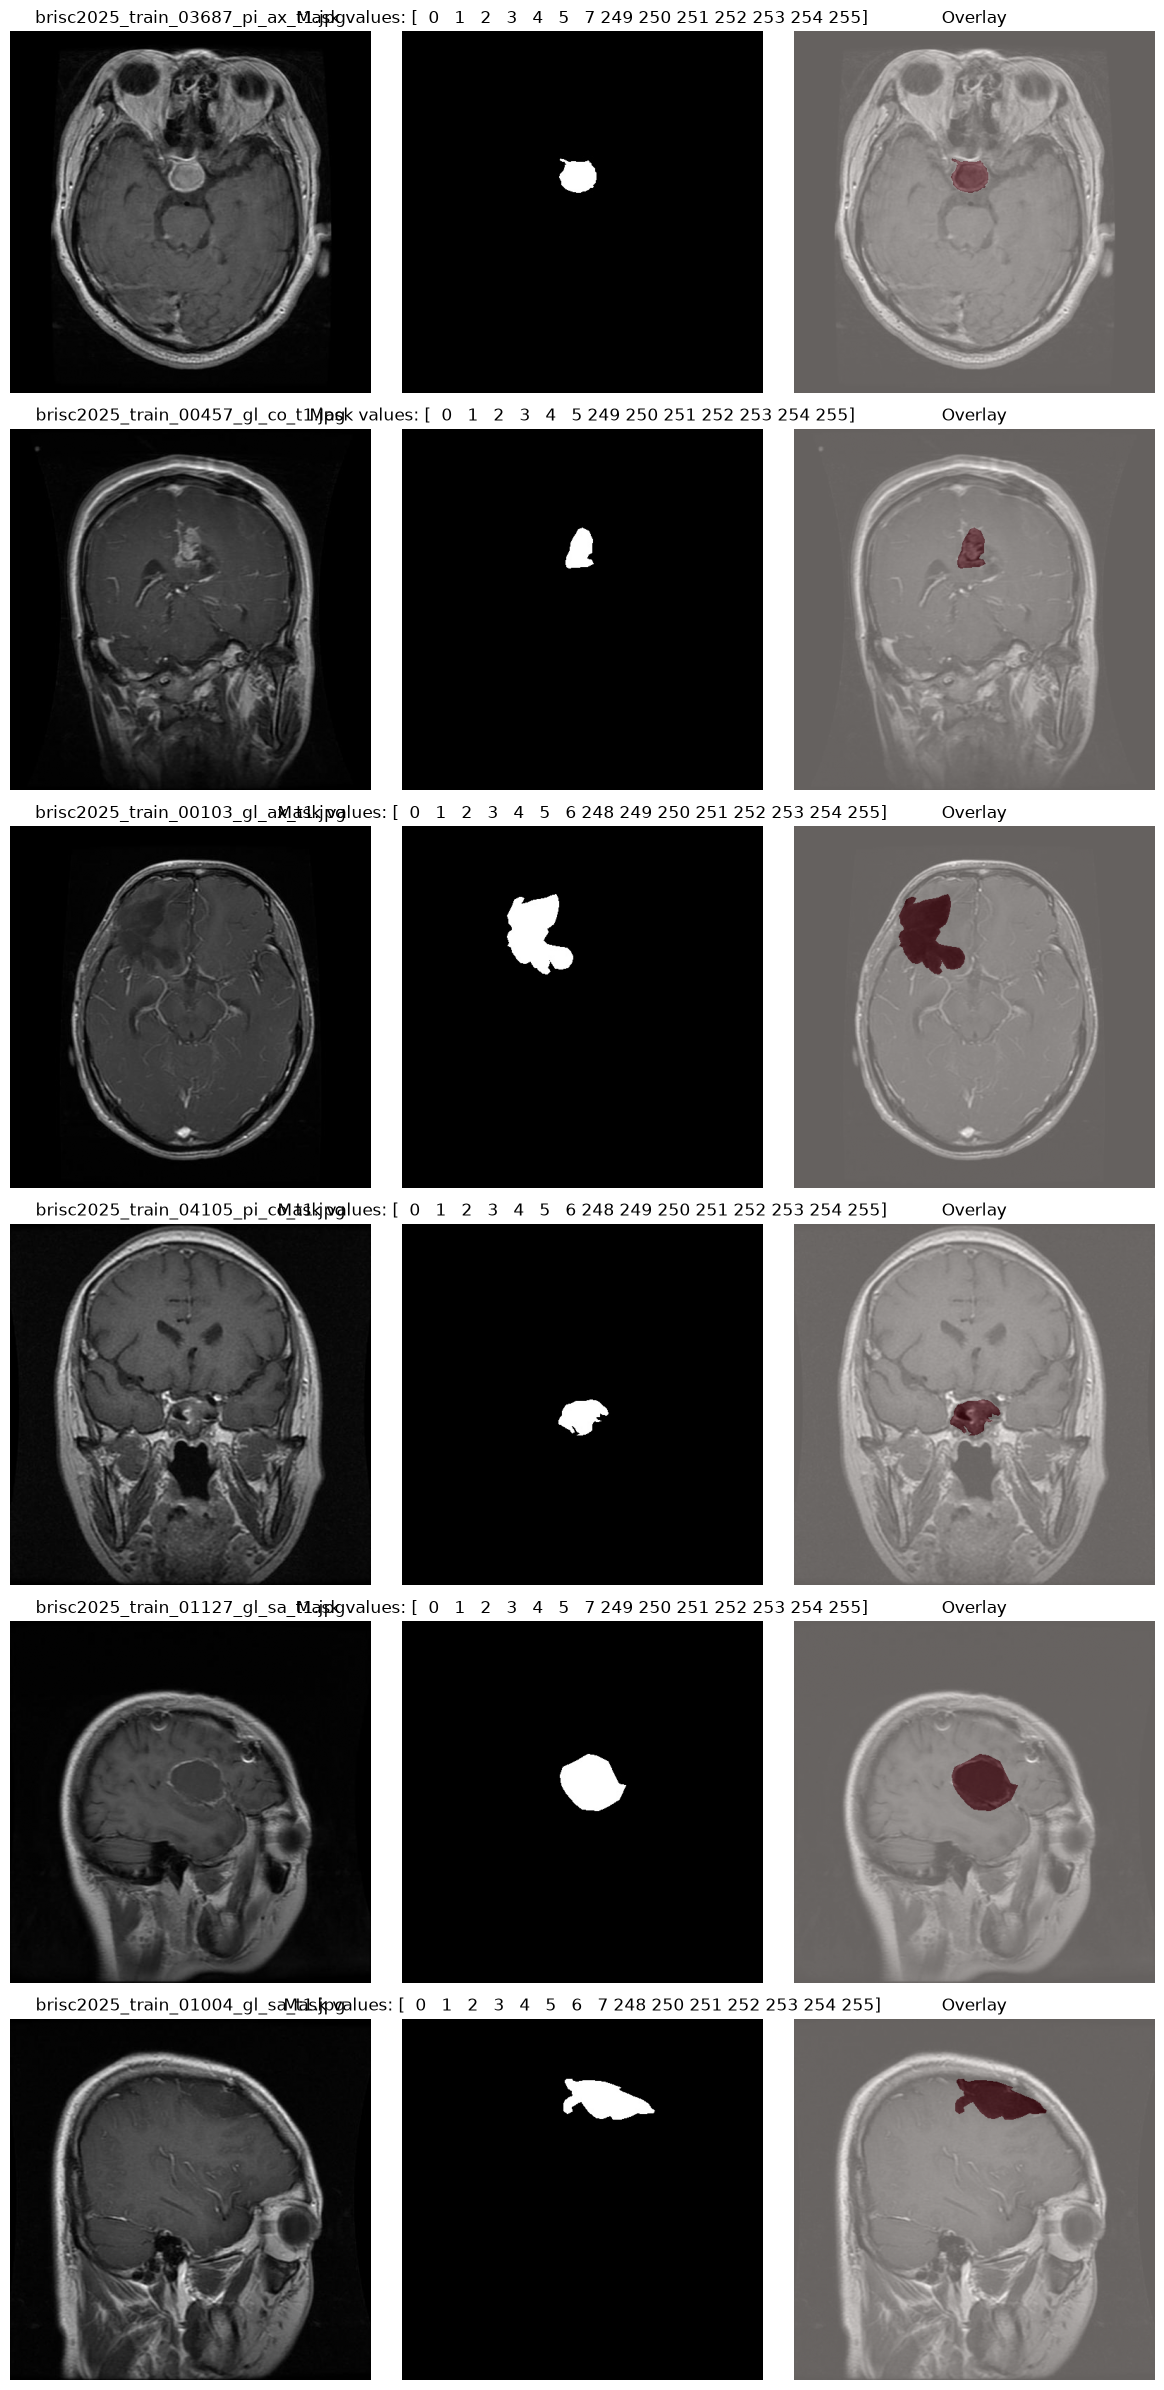

In [11]:

samples = random.Random(42).sample(valid_pairs, k=min(6, len(valid_pairs)),)

fig, axes = plt.subplots(len(samples), 3, figsize=(12, 4 * len(samples)))

for row, (image_path, mask_path) in enumerate(samples):
    image = np.asarray(Image.open(image_path).convert("L"))
    mask = np.asarray(Image.open(mask_path).convert("L"))

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(image_path.name)

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"Mask values: {np.unique(mask)}")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(mask, cmap="Reds", alpha=0.4)
    axes[row, 2].set_title("Overlay")

    for axis in axes[row]:
        axis.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20

# Use classification records as the master list because it contains all four
# classes. Stratifying on class + plane preserves both distributions.
train = manifest[
    (manifest["task"] == "classification")
    & (manifest["split"] == "train")].copy()

train["stratum"] = (
    train["tumor_label"] + "__" + train["plane_label"]
)

classification_train, classification_val = train_test_split(
    train,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=train["stratum"],
)

classification_train = classification_train.copy()
classification_val = classification_val.copy()


segmentation_images = manifest[
    (manifest["task"] == "segmentation")
    & (manifest["split"] == "train")
    & (~manifest["is_mask"])].copy()

train_names = set(classification_train["filename"])
val_names = set(classification_val["filename"])

segmentation_train = segmentation_images[
    segmentation_images["filename"].isin(train_names)
].copy()
segmentation_val = segmentation_images[
    segmentation_images["filename"].isin(val_names)
].copy()



for frame in (
    classification_train,
    classification_val,
    segmentation_train,
    segmentation_val,
):
    frame["relative_path"] = frame["relative_path"].str.replace(
        "\\", "/", regex=False
    )

for frame in (segmentation_train, segmentation_val):
    frame["mask_relative_path"] = (
        frame["relative_path"]
        .str.replace("/images/", "/masks/", regex=False)
        .str.replace(r"\.jpg$", ".png", regex=True)
    )


assert len(classification_train) + len(classification_val) == len(train)
assert train_names.isdisjoint(val_names)
assert len(segmentation_train) + len(segmentation_val) == len(segmentation_images)
assert set(segmentation_train["filename"]).isdisjoint(
    set(segmentation_val["filename"])
)


outputs = {
    "classification_train.csv": classification_train.drop(columns="stratum"),
    "classification_val.csv": classification_val.drop(columns="stratum"),
    "segmentation_train.csv": segmentation_train,
    "segmentation_val.csv": segmentation_val,
}

output_dir = Path('../data')
for filename, frame in outputs.items():
    frame.sort_values(
        ["tumor_label", "plane_label", "filename"]
    ).to_csv( output_dir/ filename, index=False)


print("Classification:", len(classification_train), "train /", len(classification_val), "val")
print("Segmentation:", len(segmentation_train), "train /", len(segmentation_val), "val")



Classification: 4000 train / 1000 val
Segmentation: 3146 train / 787 val
